# Data acquisition and exploratory data analysis (EDA)
**LLM4VKG · local CMT scenario · full dataset analysis**

The aim is to identify the data sources, assess missing values and schema completeness, measure graph sizes, and estimate the resources needed for experiments. All results are computed from the dataset directory. Source files are left unchanged.

## 1. Reference paper and data acquisition
Xiao et al. (2025), *LLM4VKG: Leveraging Large Language Models for Virtual Knowledge Graph Construction*, IJCAI, pp. 4715–4723: [paper](https://doi.org/10.24963/ijcai.2025/525).

Section 5 describes **RODI** and **RODI-T(x%)**, which removes part of the ontology vocabulary starting from leaf nodes. A benchmark sample includes a database schema, a reference ontology, and SQL–SPARQL query pairs. SQL answers provide the reference for evaluating SPARQL answers. Domains include conferences, geodata, and oil and gas. A result for one scenario is not the average across the benchmark.

Sources (checked on 2026-11-01):
- [Authors' repository](https://github.com/HomuraT/LLM4VKG) and [dataset directory](https://github.com/HomuraT/LLM4VKG/tree/main/datasets/rodi).
- [Original RODI benchmark](https://github.com/chrpin/rodi).

The local files are dump.sql, ontology.ttl, and ontology.owl. The **cmt_structured** schema and **http://cmt#** namespace indicate a restructured CMT scenario. This identification is based on file contents, **not verified equality with a specific upstream commit**. SHA-256 hashes below identify the local files. No additional datasets are included: comparability with the paper is the priority.

Full reproduction requires matching query pairs and scenario configuration from a pinned repository version, followed by verification of the data, mapping generation, and the authors' evaluation protocol. The local files support EDA but are insufficient for a comparable F1 score.

## 2. Environment and file inventory

The analysis runs offline. The local .eda_deps directory, if present, supplies additional dependencies. Section 6 requires the setup, SQL loading, and ontology cells (sections 2, 3, and 5); it recomputes its FK summary and does not require the missing-value analysis in section 4.

In [1]:
from pathlib import Path
import sys, re, hashlib, time, math, platform
import xml.etree.ElementTree as ET
from collections import Counter
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "dataset" / "dump.sql").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run the notebook from the project directory.")
if (ROOT / ".eda_deps").is_dir():
    sys.path.insert(0, str(ROOT / ".eda_deps"))
import pandas as pd
import matplotlib.pyplot as plt
import rdflib
from rdflib import Graph, RDF, RDFS, OWL, URIRef, BNode, Literal
from IPython.display import display, Markdown
start = time.perf_counter()
DATA = ROOT / "dataset"
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 100)
files = pd.DataFrame([
    {"file": p.name, "bytes": p.stat().st_size,
     "SHA256": hashlib.sha256(p.read_bytes()).hexdigest()}
    for p in sorted(DATA.iterdir()) if p.is_file()])
display(files)
print("Python:", platform.python_version(), "pandas:", pd.__version__, "rdflib:", rdflib.__version__)

,file,bytes,SHA256
0,dump.sql,291737,51febeb232104cf80775d53cac6fcc100498c44f374890b7258db10d3ef369e1
1,ontology.owl,68187,62246e45680a840b9cd871576b09f9df6269abd000c5d759700ae827bf373c75
2,ontology.ttl,32111,0e4454e9921a8f45f9105f8d4ba440d2e055fce4d42f7d1c3c587017f909a392


Python: 3.12.10 pandas: 2.2.3 rdflib: 7.6.0


## 3. SQL loading and schema completeness
The parser supports the format of this PostgreSQL dump: CREATE TABLE, COPY, and PK/FK declarations. It rejects unsupported definitions and checks row widths and block completeness. It does not execute SQL statements, including DROP SCHEMA. In COPY, \N represents NULL; empty strings are examined separately. Identifiers and case are preserved.

The shared summarize_foreign_keys function computes non-NULL reference counts and orphan references from the loaded tables and FK declarations. Both the integrity and graph sections call it explicitly.

In [2]:
sql = (DATA / "dump.sql").read_text(encoding="utf-8")
def identifiers(text):
    return [x.strip().strip('"') for x in text.split(",")]
def copy_value(value):
    if value == r"\N": return None
    escapes = {"b": "\b", "f": "\f", "n": "\n", "r": "\r", "t": "\t", "v": "\v", "\\": "\\"}
    def decode(m):
        v = m.group(1)
        if v.startswith("x"): return chr(int(v[1:], 16))
        if v[0] in "01234567": return chr(int(v, 8))
        return escapes.get(v, v)
    return re.sub(r"\\(x[0-9a-fA-F]{1,2}|[0-7]{1,3}|.)", decode, value)
schema, tables = {}, {}
for table, body in re.findall(r'CREATE TABLE "([^"]+)" \((.*?)\n\);', sql, re.S):
    columns = []
    for line in body.strip().splitlines():
        m = re.fullmatch(r'\s*(?:"([^"]+)"|(\w+))\s+(.+?)\s*,?', line)
        if not m: raise ValueError(f"Unsupported column: {line}")
        name, definition = m.group(1) or m.group(2), m.group(3).rstrip(",")
        columns.append({"table": table, "column": name, "definition": definition,
                        "not_null": "NOT NULL" in definition})
    schema[table] = columns
for table, cols, body in re.findall(
        r'COPY "([^"]+)" \((.*?)\) FROM stdin;\n(.*?)^\\\.\s*$', sql, re.S | re.M):
    cols = identifiers(cols)
    assert table not in tables
    assert cols == [c["column"] for c in schema[table]]
    rows = [line.split("\t") for line in body.splitlines()]
    assert all(len(row) == len(cols) for row in rows), table
    frame = pd.DataFrame([[copy_value(v) for v in row] for row in rows], columns=cols)
    for c in schema[table]:
        name, definition = c["column"], c["definition"]
        if definition.startswith("integer"):
            frame[name] = pd.to_numeric(frame[name], errors="raise").astype("Int64")
        elif definition.startswith("boolean"):
            assert frame[name].dropna().isin(["t", "f"]).all()
            frame[name] = frame[name].map({"t": True, "f": False}).astype("boolean")
        elif definition.startswith("date"):
            frame[name] = pd.to_datetime(frame[name], errors="raise")
        else:
            frame[name] = frame[name].astype("string")
    tables[table] = frame
assert len(schema) == len(re.findall(r"^CREATE TABLE ", sql, re.M))
assert len(tables) == len(re.findall(r"^COPY ", sql, re.M))
assert set(tables) == set(schema)
pk, fks = {}, []
constraints = re.findall(r'ALTER TABLE ONLY "([^"]+)"\s+ADD CONSTRAINT "([^"]+)" ([^;]+);', sql)
for table, name, definition in constraints:
    m = re.fullmatch(r'PRIMARY KEY \((.*?)\)', definition)
    if m:
        pk[table] = identifiers(m.group(1))
        continue
    m = re.fullmatch(r'FOREIGN KEY \((.*?)\) REFERENCES "([^"]+)"\((.*?)\)(?: ON DELETE CASCADE)?', definition)
    if not m: raise ValueError(f"Unsupported constraint: {definition}")
    fks.append({"table": table, "name": name, "columns": identifiers(m.group(1)),
                "target": m.group(2), "target_columns": identifiers(m.group(3))})
assert len(constraints) == len(re.findall(r"ADD CONSTRAINT", sql))
schema_df = pd.DataFrame([c for cols in schema.values() for c in cols])
overview = pd.DataFrame([
    {"table": t, "rows": len(df), "columns": len(df.columns),
     "NULL": int(df.isna().sum().sum()), "PK": ", ".join(pk.get(t, [])),
     "FK": sum(f["table"] == t for f in fks),
     "RAM_KiB": df.memory_usage(index=True, deep=True).sum()/1024}
    for t, df in tables.items()]).set_index("table")
display(overview)
print(f"Tables: {len(tables)}, columns: {len(schema_df)}, PK: {len(pk)}, FK: {len(fks)}")
print("Total row count:", int(overview.rows.sum()))
display(schema_df)

def summarize_foreign_keys(tables, fks):
    """Count non-NULL and orphan references for every declared FK."""
    fk_results = []
    for f in fks:
        assert f["target"] in tables
        source = tables[f["table"]][f["columns"]].dropna()
        target = set(tables[f["target"]][f["target_columns"]].dropna().itertuples(index=False, name=None))
        bad = sum(row not in target for row in source.itertuples(index=False, name=None))
        fk_results.append({"name": f["name"], "table": f["table"], "target": f["target"],
                           "non_null_references": len(source), "orphans": bad})
    return pd.DataFrame(fk_results, columns=[
        "name", "table", "target", "non_null_references", "orphans"])


,rows,columns,NULL,PK,FK,RAM_KiB
table,,,,,,
Acceptance,0,2,0,ID,0,0.128906
Administrator,0,2,0,ID,2,0.128906
Bid,0,3,0,ID,2,0.128906
Conference,7,7,21,ID,0,1.910156
Document,1468,1,0,ID,0,13.031250
Paper,734,9,3303,ID,6,132.017578
Person,774,9,774,ID,1,136.421875
Preference,0,1,0,ID,0,0.128906
ProgramCommittee,7,2,0,ID,0,0.711914


Tables: 32, columns: 85, PK: 32, FK: 52
Total row count: 5386


,table,column,definition,not_null
0,Acceptance,ID,integer NOT NULL,True
1,Acceptance,TYPE,integer DEFAULT 0,False
2,Administrator,ID,integer NOT NULL,True
3,Administrator,acceptPaper,integer,False
4,Bid,ID,integer NOT NULL,True
5,Bid,adjustedBy,integer,False
6,Bid,hasBid_Inv,integer,False
7,Conference,ID,integer NOT NULL,True
8,Conference,siteURL,character varying(22),False
9,Conference,acceptsHardcopySubmissions,character varying(199),False


## 4. Missing values and integrity
The missing-value percentage for an empty table is undefined (NaN). NULL in an optional relationship is not necessarily an error. We check empty strings, NOT NULL constraints, PK uniqueness, string lengths, and orphan FK references. FK checks follow MATCH SIMPLE semantics: a reference containing NULL is not classified as orphaned.

In [3]:
missing, integrity = [], []
for t, df in tables.items():
    for c in schema[t]:
        col, series = c["column"], df[c["column"]]
        n = int(series.isna().sum())
        missing.append({"table": t, "column": col, "rows": len(df), "NULL": n,
                        "NULL_%": 100*n/len(df) if len(df) else float("nan"),
                        "empty_strings": int(series.astype("string").str.strip().eq("").fillna(False).sum()),
                        "unique_non_null": series.nunique()})
        if c["not_null"]:
            integrity.append({"test": "NOT NULL", "object": f"{t}.{col}", "violations": n})
        limit = re.search(r"character varying\((\d+)\)", c["definition"])
        if limit:
            bad = int(series.astype("string").str.len().gt(int(limit.group(1))).fillna(False).sum())
            integrity.append({"test": "string length", "object": f"{t}.{col}", "violations": bad})
    if t in pk:
        integrity.extend([
            {"test": "PK NULL", "object": t, "violations": int(df[pk[t]].isna().any(axis=1).sum())},
            {"test": "PK duplicates", "object": t, "violations": int(df.duplicated(pk[t]).sum())}])
missing_df = pd.DataFrame(missing)
fk_df = summarize_foreign_keys(tables, fks)
integrity_df = pd.DataFrame(integrity)
display(missing_df)
display(integrity_df.groupby("test", as_index=False).violations.sum())
display(fk_df)
print("Tables without a PK:", sorted(set(tables)-set(pk)))
print("Empty tables:", overview.index[overview.rows.eq(0)].tolist())
print("Duplicate full rows:", sum(int(df.duplicated().sum()) for df in tables.values()))

,table,column,rows,NULL,NULL_%,empty_strings,unique_non_null
0,Acceptance,ID,0,0,NaN,0,0
1,Acceptance,TYPE,0,0,NaN,0,0
2,Administrator,ID,0,0,NaN,0,0
3,Administrator,acceptPaper,0,0,NaN,0,0
4,Bid,ID,0,0,NaN,0,0
5,Bid,adjustedBy,0,0,NaN,0,0
6,Bid,hasBid_Inv,0,0,NaN,0,0
7,Conference,ID,7,0,0.0,0,7
8,Conference,siteURL,7,0,0.0,0,7
9,Conference,acceptsHardcopySubmissions,7,7,100.0,0,0


,test,violations
0,NOT NULL,0
1,PK NULL,0
2,PK duplicates,0
3,string length,0


,name,table,target,non_null_references,orphans
0,Administrator_ID_fkey,Administrator,Person,0,0
1,Bid_adjustedBy_fkey,Bid,Person,0,0
2,FKAdministratoracceptPaper,Administrator,Paper,0,0
3,FKBidhasBid_Inv,Bid,Paper,0,0
4,FKPaperURI,Paper,Document,734,0
5,FKPaperacceptedBy,Paper,Administrator,0,0
6,FKPaperrejectedBy,Paper,Administrator,0,0
7,FKReviewURI,Review,Document,734,0
8,FKassignReviewerAdministrator,assignReviewer,Administrator,0,0
9,FKassignedToPaper,assignedTo,Paper,734,0


Tables without a PK: []
Empty tables: ['Acceptance', 'Administrator', 'Bid', 'Preference', 'SubjectArea', 'assignReviewer', 'detailsEnteredBy', 'enableVirtualMeeting', 'endReview', 'enterReviewCriteria', 'finalizePaperAssignment', 'hardcopyMailingManifestsP', 'hasConflictOfInterest', 'hasSubjectArea', 'markConflictOfInterest', 'paperAssignmentToolsRunBy', 'readByReviewer', 'reviewerBiddingStartedBy', 'setMaxPapers', 'submitPaper']
Duplicate full rows: 0


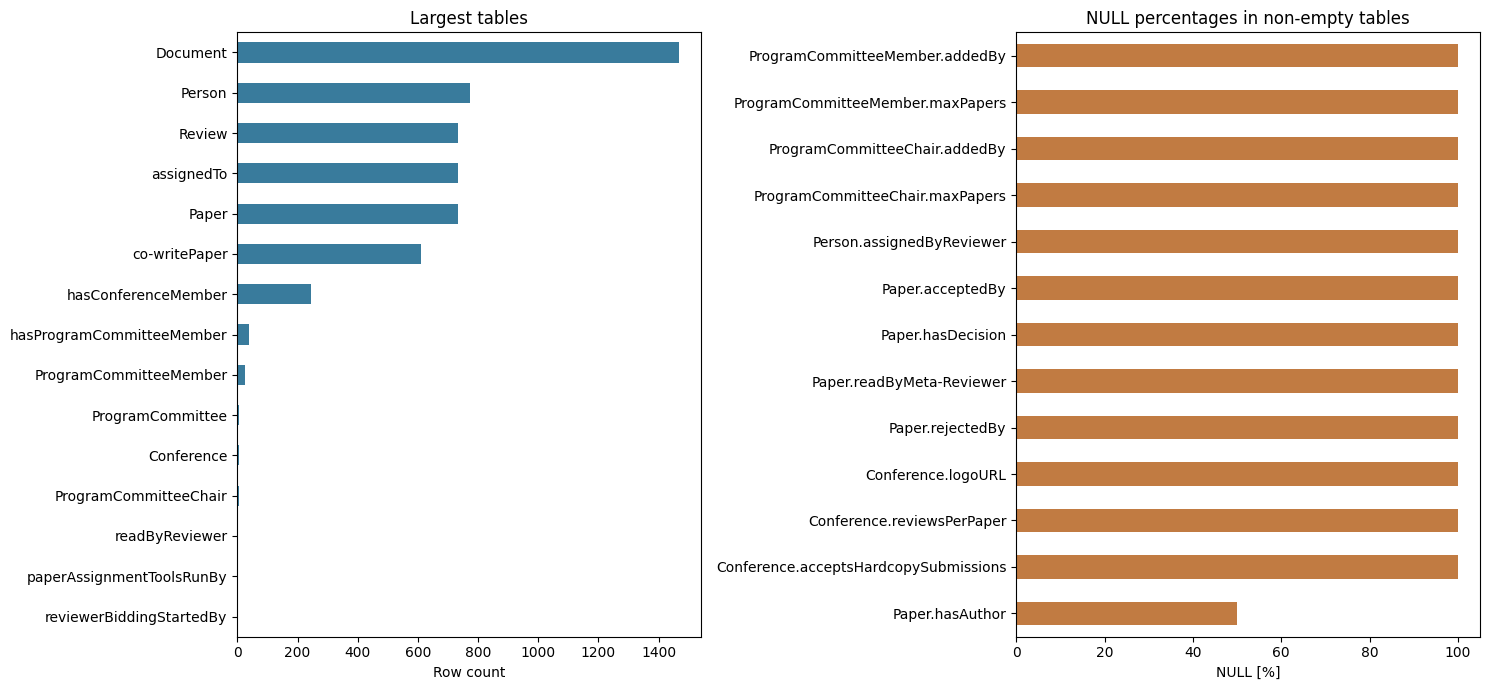

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
overview.rows.sort_values().tail(15).plot.barh(ax=axes[0], color="#397b9c")
axes[0].set(title="Largest tables", xlabel="Row count", ylabel="")
plot_missing = missing_df.loc[missing_df.NULL.gt(0)].copy()
plot_missing["field"] = plot_missing.table + "." + plot_missing.column
if len(plot_missing):
    plot_missing.set_index("field")["NULL_%"].sort_values().tail(15).plot.barh(ax=axes[1], color="#c17b42")
axes[1].set(title="NULL percentages in non-empty tables", xlabel="NULL [%]", ylabel="", xlim=(0, 105))
plt.tight_layout()
plt.show()

## 5. Ontology completeness and graph size
TTL is parsed as RDF. The .owl file uses **OWL/XML**, not RDF/XML, so its declarations are read with an XML parser. Matching declarations do not prove equivalence of all axioms.

The ontology graph includes blank nodes and literals. RDF triple counts are reported separately from edges between resources. No OWL inference is performed. A missing explicit domain, range, or label is a review item, not automatically an ontology error.

In [5]:
g = Graph().parse(DATA / "ontology.ttl", format="turtle")
classes = {s for s in g.subjects(RDF.type, OWL.Class) if isinstance(s, URIRef)}
objects = set(g.subjects(RDF.type, OWL.ObjectProperty))
datatypes = set(g.subjects(RDF.type, OWL.DatatypeProperty))
def short(node): return str(node).rsplit("#", 1)[-1]
property_df = pd.DataFrame([
    {"property": short(p), "type": kind,
     "domain": ", ".join(sorted(short(x) for x in g.objects(p, RDFS.domain))),
     "range": ", ".join(sorted(short(x) for x in g.objects(p, RDFS.range))),
     "label": " | ".join(str(x) for x in g.objects(p, RDFS.label))}
    for kind, props in [("object", objects), ("data", datatypes)]
    for p in sorted(props, key=str)])
display(property_df)
display(property_df.groupby("type").agg(
    count=("property", "size"), missing_domain=("domain", lambda s: s.eq("").sum()),
    missing_range=("range", lambda s: s.eq("").sum()), missing_label=("label", lambda s: s.eq("").sum())))
vertices = set(g.subjects()) | set(g.objects())
resources = {v for v in vertices if not isinstance(v, Literal)}
ontology_stats = {
    "RDF triples": len(g), "S ∪ O nodes (including literals)": len(vertices),
    "URI/BNode resources in S ∪ O": len(resources),
    "blank nodes": sum(isinstance(v, BNode) for v in vertices),
    "literals (distinct RDF terms)": sum(isinstance(v, Literal) for v in vertices),
    "edges to resources": sum(not isinstance(o, Literal) for s,p,o in g),
    "distinct RDF predicates": len(set(g.predicates())), "named classes": len(classes),
    "object properties": len(objects), "data properties": len(datatypes),
    "explicit owl:NamedIndividual": len(set(g.subjects(RDF.type, OWL.NamedIndividual))),
    "subjects explicitly typed with a domain class": len({s for s,p,o in g.triples((None,RDF.type,None)) if o in classes})}
display(pd.Series(ontology_stats, name="value").to_frame())
display(pd.DataFrame(Counter(str(p) for p in g.predicates()).most_common(), columns=["RDF predicate", "triples"]))
xml = ET.parse(DATA / "ontology.owl").getroot()
xml_sets = {}
for tag in ["Class", "ObjectProperty", "DataProperty"]:
    xml_sets[tag] = {
        URIRef("http://cmt" + e.attrib["IRI"] if e.attrib["IRI"].startswith("#") else e.attrib["IRI"])
        for e in xml.findall(f"owl:Declaration/owl:{tag}", {"owl": str(OWL)})}
display(pd.DataFrame([
    {"kind": tag, "TTL": len(terms), "OWL_XML": len(xml_sets[tag]),
     "only_TTL": sorted(map(str, terms-xml_sets[tag])),
     "only_OWL_XML": sorted(map(str, xml_sets[tag]-terms))}
    for tag, terms in [("Class", classes), ("ObjectProperty", objects), ("DataProperty", datatypes)]]))

,property,type,domain,range,label
0,acceptPaper,object,Administrator,Paper,accept paper
1,acceptedBy,object,Paper,Administrator,accepted by
2,addProgramCommitteeMember,object,Administrator,ProgramCommitteeMember,add program committee member
3,addedBy,object,ProgramCommitteeMember,Administrator,added by
4,adjustBid,object,Reviewer,Bid,adjust bid
5,adjustedBy,object,Bid,Reviewer,adjusted by
6,assignExternalReviewer,object,Reviewer,ExternalReviewer,assign external reviewer
7,assignReviewer,object,Administrator,Reviewer,assign reviewer
8,assignedByAdministrator,object,Reviewer,Administrator,assigned by administrator
9,assignedByReviewer,object,ExternalReviewer,Reviewer,assigned by reviewer


,count,missing_domain,missing_range,missing_label
type,,,,
data,11,0,1,0
object,49,0,0,0


,value
RDF triples,468
S ∪ O nodes (including literals),229
URI/BNode resources in S ∪ O,126
blank nodes,19
literals (distinct RDF terms),103
edges to resources,359
distinct RDF predicates,16
named classes,30
object properties,49
data properties,11


,RDF predicate,triples
0,http://www.w3.org/1999/02/22-rdf-syntax-ns#type,132
1,http://www.w3.org/2000/01/rdf-schema#label,89
2,http://www.w3.org/2000/01/rdf-schema#domain,60
3,http://www.w3.org/2000/01/rdf-schema#range,59
4,http://www.w3.org/2000/01/rdf-schema#subClassOf,33
5,http://www.w3.org/2002/07/owl#disjointWith,27
6,http://www.w3.org/2002/07/owl#inverseOf,20
7,http://www.w3.org/2000/01/rdf-schema#comment,12
8,http://www.w3.org/1999/02/22-rdf-syntax-ns#first,8
9,http://www.w3.org/1999/02/22-rdf-syntax-ns#rest,8


,kind,TTL,OWL_XML,only_TTL,only_OWL_XML
0,Class,30,30,[],[]
1,ObjectProperty,49,49,[],[]
2,DataProperty,11,11,[],[]


## 6. Relationships and the data graph
We distinguish the SQL schema graph (tables and FK declarations), a diagnostic record graph (each node is a table–PK pair and each edge is a valid FK reference), and the RDF ontology graph.

The record graph **is not a materialized VKG**. Junction-table records are separate nodes here. Inheritance, identifier merging, and junction-table transformations require mappings. Without these, the number of unique entities and triples in the target VKG is unknown. TTL and OWL are not two independent datasets.

The FK summary is computed again in this section, so skipping the missing-value analysis does not leave fk_df undefined.

In [6]:
# Recompute the FK summary; this section does not depend on section 4.
fk_df = summarize_foreign_keys(tables, fks)

record_nodes = set()
for t, df in tables.items():
    assert t in pk, f"Missing record identity: {t}"
    record_nodes.update((t, tuple(row)) for row in df[pk[t]].itertuples(index=False, name=None))
record_edges = []
for f in fks:
    source, target = tables[f["table"]], tables[f["target"]]
    lookup = {}
    for _, row in target.iterrows():
        key = tuple(row[c] for c in f["target_columns"])
        lookup.setdefault(key, []).append((f["target"], tuple(row[c] for c in pk[f["target"]])))
    for _, row in source.iterrows():
        key = tuple(row[c] for c in f["columns"])
        if any(pd.isna(v) for v in key): continue
        a = (f["table"], tuple(row[c] for c in pk[f["table"]]))
        for b in lookup.get(key, []): record_edges.append((a, f["name"], b))
touched = {v for a, label, b in record_edges for v in (a,b)}
assert touched <= record_nodes
display(pd.Series({
    "SQL schema nodes": len(tables), "schema FK edges": len(fks),
    "record graph nodes": len(record_nodes), "record graph edges": len(record_edges),
    "active FK types": len({label for a,label,b in record_edges}),
    "isolated records under explicit FKs": len(record_nodes-touched)}, name="value").to_frame())
junctions = [t for t, df in tables.items() if len(df.columns)==2 and set(pk[t])==set(df.columns)]
print("Candidate junction tables: two columns forming the entire PK")
display(overview.loc[junctions, ["rows", "FK"]])
display(fk_df.sort_values("non_null_references", ascending=False).head(15))
class_names = {short(c) for c in classes}
display(pd.DataFrame({
    "classes without a same-name table": pd.Series(sorted(class_names-set(tables))),
    "tables without a same-name class": pd.Series(sorted(set(tables)-class_names))}).fillna(""))
uncovered = [(t, c) for t in junctions for c in tables[t].columns
             if not any(f["table"]==t and c in f["columns"] for f in fks)]
print("Junction-table columns without an explicit FK:", uncovered)
display(pd.DataFrame([
    {"table": t, "column": c, "distribution": str(df[c].value_counts(dropna=False).to_dict())}
    for t, df in tables.items() for c in df.columns if c=="TYPE" or c.lower().startswith("is_")]))

,value
SQL schema nodes,32
schema FK edges,52
record graph nodes,5386
record graph edges,5822
active FK types,13
isolated records under explicit FKs,0


Candidate junction tables: two columns forming the entire PK


,rows,FK
table,,
assignReviewer,0,2
assignedTo,734,2
co-writePaper,612,2
detailsEnteredBy,0,2
enableVirtualMeeting,0,2
endReview,0,2
enterReviewCriteria,0,2
finalizePaperAssignment,0,2
hardcopyMailingManifestsP,0,2


,name,table,target,non_null_references,orphans
7,FKReviewURI,Review,Document,734,0
9,FKassignedToPaper,assignedTo,Paper,734,0
4,FKPaperURI,Paper,Document,734,0
44,assignedTo_Reviewer_fkey,assignedTo,Person,734,0
42,Review_writtenBy_fkey,Review,Person,734,0
45,co-writePaper_Co-author_fkey,co-writePaper,Person,612,0
10,FKco-writePaperPaper,co-writePaper,Paper,612,0
34,Paper_hasAuthor_fkey,Paper,Person,367,0
21,FKhasConferenceMemberConf,hasConferenceMember,Conference,245,0
22,FKhasConferenceMemberPers,hasConferenceMember,Person,245,0


,classes without a same-name table,tables without a same-name class
0,AssociatedChair,assignReviewer
1,Author,assignedTo
2,AuthorNotReviewer,co-writePaper
3,Chairman,detailsEnteredBy
4,Co-author,enableVirtualMeeting
5,ConferenceChair,endReview
6,ConferenceMember,enterReviewCriteria
7,Decision,finalizePaperAssignment
8,ExternalReviewer,hardcopyMailingManifestsP
9,Meta-Review,hasConferenceMember


Junction-table columns without an explicit FK: [('hasProgramCommitteeMember', 'ProgramCommitteeMember'), ('markConflictOfInterest', 'ConferenceMember'), ('setMaxPapers', 'ProgramCommitteeMember')]


,table,column,distribution
0,Acceptance,TYPE,{}
1,Paper,TYPE,"{np.int64(2): 367, np.int64(1): 367}"
2,Person,is_user,{np.True_: 774}
3,Person,is_Reviewer,"{np.True_: 477, np.False_: 297}"
4,Person,is_Author,"{np.True_: 564, np.False_: 210}"
5,Person,is_Co-author,"{np.True_: 402, np.False_: 372}"
6,Person,TYPE,{np.int64(1): 774}
7,Review,TYPE,{np.int64(0): 734}


## 7. Preprocessing and resource requirements
- Preserve raw files and checksums. Use PostgreSQL for experiments as described in the authors' repository; the EDA parser does not replace an import test.
- Preserve NULL values and empty tables. Do not automatically impute relationships or remove empty attributes: they may reflect the scenario design.
- Preserve quoted SQL names, including names containing hyphens. Numeric, date, and Boolean values are checked during loading.
- Clarify TYPE values, role flags, inheritance, and junction tables. The absence of a separate table does not imply the absence of class instances.
- Review columns without FKs and declaration differences between TTL and OWL/XML. Name matching does not validate semantic mappings.
- Obtain matching evaluation queries and pin the dataset version. An arbitrary record-level train/test split does not replace the RODI protocol.

In [7]:
total_rows = int(overview.rows.sum())
memory_mib = sum(df.memory_usage(index=True, deep=True).sum() for df in tables.values())/2**20
sample_n = math.ceil(total_rows*0.01)
budget_hours, minutes_per_item = 8, 5
capacity = int(budget_hours*60/minutes_per_item)
display(pd.Series({
    "source files [MiB]": files.bytes.sum()/2**20,
    "DataFrames including index [MiB]": memory_mib,
    "rows in a 1% sample (rounded up)": sample_n,
    "reviewing 1% at 5 min/row [h]": sample_n*minutes_per_item/60,
    "items reviewable in 8 h": capacity,
    "share of rows within this budget [%]": min(100, 100*capacity/total_rows),
    "FK types to review": len(fks),
    "reviewing all FK types at 5 min/type [h]": len(fks)*minutes_per_item/60
}, name="estimate").to_frame())
print(f"Time since analysis started: {time.perf_counter()-start:.2f} s (depends on hardware and execution method).")

,estimate
source files [MiB],0.373874
DataFrames including index [MiB],0.481750
rows in a 1% sample (rounded up),54.000000
reviewing 1% at 5 min/row [h],4.500000
items reviewable in 8 h,96.000000
share of rows within this budget [%],1.782399
FK types to review,52.000000
reviewing all FK types at 5 min/type [h],4.333333


Time since analysis started: 4.43 s (depends on hardware and execution method).


## 8. Brief EDA conclusions

In [8]:
null_count = int(missing_df.NULL.sum())
cell_count = sum(df.size for df in tables.values())
empty_tables = int(overview.rows.eq(0).sum())
bad_constraints = int(integrity_df.violations.sum())
orphans = int(fk_df.orphans.sum())
full_missing = missing_df[(missing_df.rows > 0) & (missing_df.NULL == missing_df.rows)]
display(Markdown(f'''
- The dataset contains **{len(tables)} tables, {len(schema_df)} columns, and {total_rows:,} rows**; **{empty_tables} tables are empty**. The analysis covers 100% of local data.
- There are **{null_count:,} NULL values ({100*null_count/cell_count:.2f}% of cells)**. In non-empty tables, **{len(full_missing)} columns** are entirely NULL. These require semantic interpretation rather than automatic imputation.
- PK, NOT NULL, and string-length checks found **{bad_constraints} violations**; FK checks found **{orphans} orphan references**. These results apply only to declared constraints.
- Relationships are present: **{len(fks)} FK declarations**, **{len(objects)} object properties**, and **{len(record_edges):,} valid references between records**. Not every declaration has instances.
- The ontology contains **{len(g)} RDF triples** and **{len(vertices)} S ∪ O nodes including literals**. The diagnostic graph contains **{len(record_nodes):,} record nodes**, which is not the number of entities in the target VKG.
- DataFrames occupy approximately **{memory_mib:.2f} MiB**. Full EDA can run on a CPU. Mapping correctness, rather than data volume, is the main challenge for the next stage.
- Comparison with the paper requires matching query pairs, a verified scenario version, and mappings. Manual annotation of the entire dataset is unnecessary.
'''))


- The dataset contains **32 tables, 85 columns, and 5,386 rows**; **20 tables are empty**. The analysis covers 100% of local data.
- There are **4,164 NULL values (19.46% of cells)**. In non-empty tables, **12 columns** are entirely NULL. These require semantic interpretation rather than automatic imputation.
- PK, NOT NULL, and string-length checks found **0 violations**; FK checks found **0 orphan references**. These results apply only to declared constraints.
- Relationships are present: **52 FK declarations**, **49 object properties**, and **5,822 valid references between records**. Not every declaration has instances.
- The ontology contains **468 RDF triples** and **229 S ∪ O nodes including literals**. The diagnostic graph contains **5,386 record nodes**, which is not the number of entities in the target VKG.
- DataFrames occupy approximately **0.48 MiB**. Full EDA can run on a CPU. Mapping correctness, rather than data volume, is the main challenge for the next stage.
- Comparison with the paper requires matching query pairs, a verified scenario version, and mappings. Manual annotation of the entire dataset is unnecessary.
